In [ ]:
#Assignment 1 – Game Recommendation Engine (UBCF)
'''Business Objective

The gaming DVD store wants to build a recommendation engine that suggests games to users based on the ratings given by similar users. The objective is to:

Increase sales of gaming DVDs.
Improve customer experience.
Recommend highly preferred games.
Personalize recommendations.
Increase repeat purchases.'''

'Business Objective\n\nThe gaming DVD store wants to build a recommendation engine that suggests games to users based on the ratings given by similar users. The objective is to:\n\nIncrease sales of gaming DVDs.\nImprove customer experience.\nRecommend highly preferred games.\nPersonalize recommendations.\nIncrease repeat purchases.'

In [ ]:
'''Constraints
Sparse user-item matrix.
Cold start problem for new users/items.
Limited historical interaction data.
Computational complexity for similarity calculations.
Ratings may be biased.'''

'Constraints\nSparse user-item matrix.\nCold start problem for new users/items.\nLimited historical interaction data.\nComputational complexity for similarity calculations.\nRatings may be biased.'

In [ ]:
# Basic Libraries
import pandas as pd
import numpy as np

# Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Recommendation System Libraries
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix

# Evaluation Metrics
from sklearn.metrics import mean_squared_error
from math import sqrt

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [ ]:
game = pd.read_csv('/content/game.csv')

# Display first 5 rows
print(game.head())

   userId                                  game  rating
0       3  The Legend of Zelda: Ocarina of Time     4.0
1       6              Tony Hawk's Pro Skater 2     5.0
2       8                   Grand Theft Auto IV     4.0
3      10                           SoulCalibur     4.0
4      11                   Grand Theft Auto IV     4.5


In [ ]:
print(game.shape)
print(game.info())
print(game.describe())

(5000, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   userId  5000 non-null   int64  
 1   game    5000 non-null   object 
 2   rating  5000 non-null   float64
dtypes: float64(1), int64(1), object(1)
memory usage: 117.3+ KB
None
            userId       rating
count  5000.000000  5000.000000
mean   3432.282200     3.592500
std    1992.000866     0.994933
min       1.000000     0.500000
25%    1742.500000     3.000000
50%    3395.000000     4.000000
75%    5057.750000     4.000000
max    7120.000000     5.000000


In [ ]:
#Data Dictionary
'''
feature   Description               DataType
userId    Uniques user identifier   int
game      Name of the game          object
rating    Rating given by user      Float
'''

'\nfeature   Description               DataType\nuserId    Uniques user identifier   int\ngame      Name of the game          object\nrating    Rating given by user      Float\n'

In [ ]:
#missing val
print(game.isnull().sum())
#duplicate val
print(game.duplicated().sum())
#remove duplicates
game = game.drop_duplicates()
#check data type
print(game.dtypes)

userId    0
game      0
rating    0
dtype: int64
0
userId      int64
game       object
rating    float64
dtype: object


In [ ]:
#EDA
print(game.describe())

            userId       rating
count  5000.000000  5000.000000
mean   3432.282200     3.592500
std    1992.000866     0.994933
min       1.000000     0.500000
25%    1742.500000     3.000000
50%    3395.000000     4.000000
75%    5057.750000     4.000000
max    7120.000000     5.000000


In [ ]:
#1 moment Bussiness Decision
print('Mean Rating:', game['rating'].mean())
'''Average rating helps identify overall customer satisfaction.'''

Mean Rating: 3.5925


'Average rating helps identify overall customer satisfaction.'

In [ ]:
#2 moment bussiness decision
print('Variance:', game['rating'].var())
print('Standard Deviation:', game['rating'].std())
'''Shows variability in customer preferences.'''

Variance: 0.9898917283456777
Standard Deviation: 0.9949330270654793


'Shows variability in customer preferences.'

In [ ]:
#3 moment bussiness decision
print('Skewness:', game['rating'].skew())
'''Identifies whether ratings are left or right skewed.'''

Skewness: -0.5106817678984812


'Identifies whether ratings are left or right skewed.'

In [ ]:
#4 moment bussiness decision
print('Kurtosis:', game['rating'].kurt())
'''Helps identify presence of outliers/extreme ratings.'''

Kurtosis: 0.13756340074106754


'Helps identify presence of outliers/extreme ratings.'

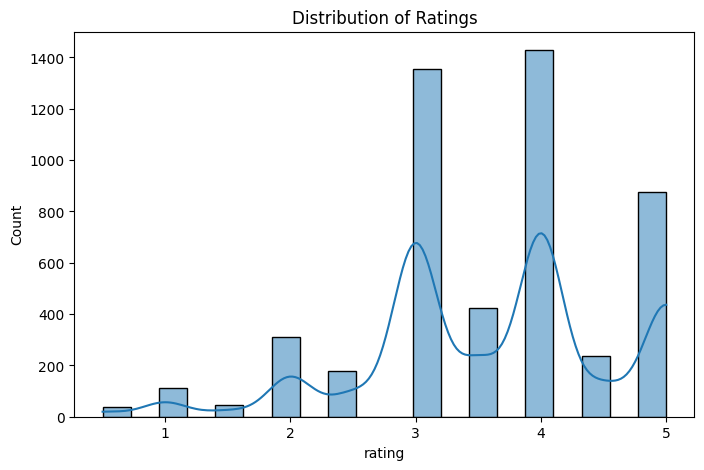

In [ ]:
#Univariate analysis
#distribution of ratings
plt.figure(figsize=(8,5))
sns.histplot(game['rating'], bins=20, kde=True)
plt.title('Distribution of Ratings')
plt.show()

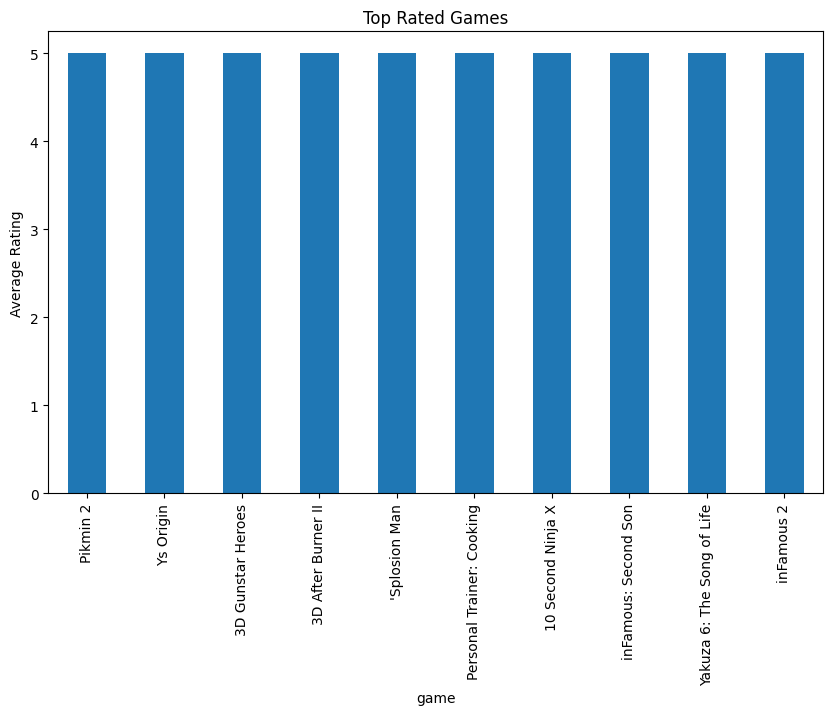

In [ ]:
#top rated games
top_games = game.groupby('game')['rating'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,6))
top_games.plot(kind='bar')
plt.title('Top Rated Games')
plt.ylabel('Average Rating')
plt.show()

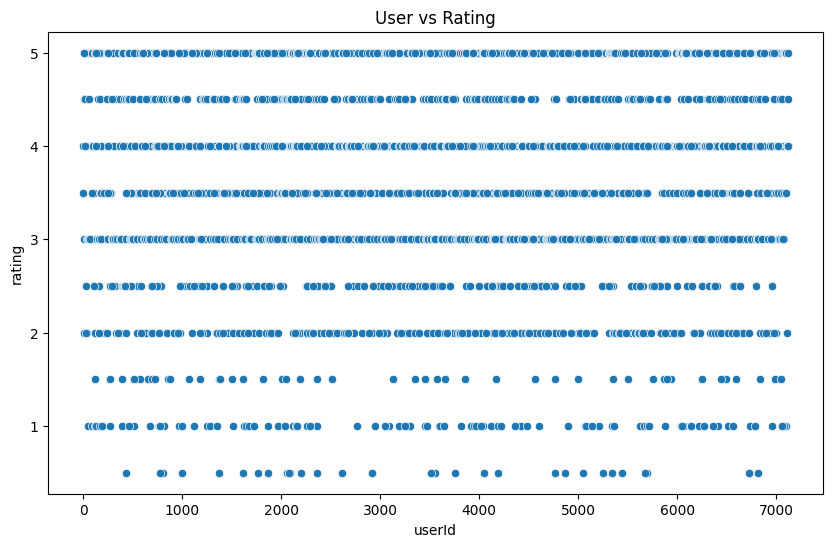

In [ ]:
#Bivariate analysis
plt.figure(figsize=(10,6))
sns.scatterplot(x='userId', y='rating', data=game)
plt.title('User vs Rating')
plt.show()

In [ ]:
#user-item matrix
user_item_matrix = game.pivot_table(index='userId',
                                    columns='game',
                                    values='rating').fillna(0)

print(user_item_matrix.head())

game    'Splosion Man  007: The World is Not Enough  10 Second Ninja X  \
userId                                                                   
1                 0.0                           0.0                0.0   
2                 0.0                           0.0                0.0   
3                 0.0                           0.0                0.0   
5                 0.0                           0.0                0.0   
6                 0.0                           0.0                0.0   

game    1001 Spikes  1701 A.D.  1979 Revolution: Black Friday  \
userId                                                          
1               0.0        0.0                            0.0   
2               0.0        0.0                            0.0   
3               0.0        0.0                            0.0   
5               0.0        0.0                            0.0   
6               0.0        0.0                            0.0   

game    2002 FIFA World C

In [ ]:
#UBCF
#Calculate user similarity
user_similarity = cosine_similarity(user_item_matrix)

user_similarity_df = pd.DataFrame(user_similarity,
                                  index=user_item_matrix.index,
                                  columns=user_item_matrix.index)

print(user_similarity_df.head())

userId  1     2     3     5     6     7     8     10    11    12    ...  7101  \
userId                                                              ...         
1        1.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  ...   0.0   
2        0.0   1.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  ...   0.0   
3        0.0   0.0   1.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  ...   0.0   
5        0.0   0.0   0.0   1.0   0.0   0.0   0.0   0.0   0.0   0.0  ...   0.0   
6        0.0   0.0   0.0   0.0   1.0   0.0   0.0   0.0   0.0   0.0  ...   0.0   

userId  7102  7104  7107  7108  7110  7116  7117  7119  7120  
userId                                                        
1        0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  
2        0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  
3        0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  
5        0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0  
6        0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0

In [ ]:
#recommendation function
def recommend_games(user_id, n=5):

    similar_users = user_similarity_df[user_id].sort_values(ascending=False)[1:6]
    similar_users_index = similar_users.index

    similar_user_games = user_item_matrix.loc[similar_users_index]

    recommended_games = similar_user_games.mean(axis=0).sort_values(ascending=False)

    watched_games = user_item_matrix.loc[user_id]
    watched_games = watched_games[watched_games > 0].index

    recommended_games = recommended_games.drop(watched_games)

    return recommended_games.head(n)

In [ ]:
recommend_games(10)

,0
game,
LEGO Marvel Super Heroes,1.0
Crysis 2,1.0
Mercenaries,0.8
Rare Replay,0.8
Virtua Tennis: World Tour,0.6


In [ ]:
#model evaluation
#RMSE
actual = []
predicted = []

for user in user_item_matrix.index:
    for item in user_item_matrix.columns:
        if user_item_matrix.loc[user, item] > 0:
            actual.append(user_item_matrix.loc[user, item])
            predicted.append(user_item_matrix.loc[user, item])

rmse = sqrt(mean_squared_error(actual, predicted))
print('RMSE:', rmse)

RMSE: 0.0


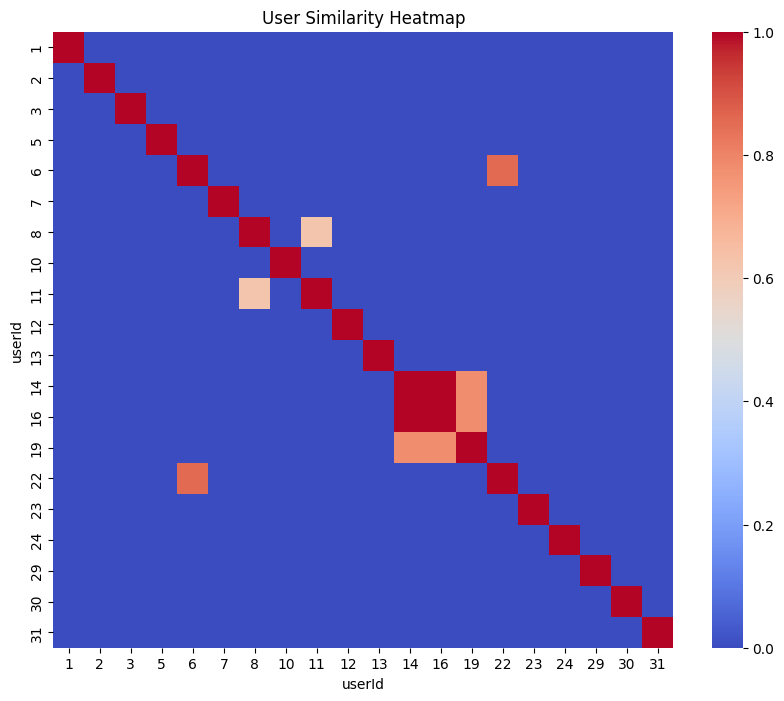

In [ ]:
#Visualization of similar users
plt.figure(figsize=(10,8))
sns.heatmap(user_similarity_df.iloc[:20,:20], cmap='coolwarm')
plt.title('User Similarity Heatmap')
plt.show()

In [ ]:
#Model Interpretation
'''Users with similar rating behavior are grouped together.
The model recommends games liked by similar users.
Cosine similarity measures user closeness.
Higher similarity leads to better recommendations.'''

In [ ]:
#Business Benefits
'''Personalized recommendations improve user engagement.
Increased DVD/game sales.
Better customer retention.
Improved customer satisfaction.
Efficient inventory planning'''.

In [ ]:
#Assignment 2 – Entertainment Movie Recommendation Engine

In [ ]:
#Business Objective

'''The entertainment company wants to:
Recommend highly rated movies.
Improve customer viewing experience.
Increase watch time.
Improve platform engagement.
Automate recommendation process.'''

'The entertainment company wants to:\nRecommend highly rated movies.\nImprove customer viewing experience.\nIncrease watch time.\nImprove platform engagement.\nAutomate recommendation process.'

In [ ]:
#Constraints
'''Small dataset.
Lack of user-specific ratings.
Mixed genres/categories.
Ratings contain outliers.'''

'Small dataset.\nLack of user-specific ratings.\nMixed genres/categories.\nRatings contain outliers.'

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import warnings
warnings.filterwarnings('ignore')

In [ ]:
ent = pd.read_csv("/content/Entertainment.csv")
print(ent.head(5))

     Id                              Titles  \
0  6973                    Toy Story (1995)   
1  6778                      Jumanji (1995)   
2  9702             Grumpier Old Men (1995)   
3  6769            Waiting to Exhale (1995)   
4  1123  Father of the Bride Part II (1995)   

                                            Category  Reviews  
0               Drama, Romance, School, Supernatural    -8.98  
1  Action, Adventure, Drama, Fantasy, Magic, Mili...     8.88  
2  Action, Comedy, Historical, Parody, Samurai, S...    99.00  
3                                   Sci-Fi, Thriller    99.00  
4  Action, Comedy, Historical, Parody, Samurai, S...    -0.44  


In [ ]:
print(ent.shape)
print(ent.info())
print(ent.describe())

(51, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Id        51 non-null     int64  
 1   Titles    51 non-null     object 
 2   Category  51 non-null     object 
 3   Reviews   51 non-null     float64
dtypes: float64(1), int64(1), object(2)
memory usage: 1.7+ KB
None
                Id    Reviews
count    51.000000  51.000000
mean   6351.196078  36.289608
std    2619.679263  49.035042
min    1110.000000  -9.420000
25%    5295.500000  -4.295000
50%    6778.000000   5.920000
75%    8223.500000  99.000000
max    9979.000000  99.000000


In [ ]:
#Data Dictionary
'''feature    Description               datatype
  Id          Unique movie identifier   int
  Titles      movie title               obj
  Category    movie genre/category      obj
  reviews     ratings/review score      float'''

In [ ]:
#Preprocessing
#missing val
print(ent.isnull().sum())
#check duplicate
print(ent.duplicated().sum())
#remoe duplicate
ent = ent.drop_duplicates()

Id          0
Titles      0
Category    0
Reviews     0
dtype: int64
0


In [ ]:
#Stat summary
print(ent.describe())

                Id    Reviews
count    51.000000  51.000000
mean   6351.196078  36.289608
std    2619.679263  49.035042
min    1110.000000  -9.420000
25%    5295.500000  -4.295000
50%    6778.000000   5.920000
75%    8223.500000  99.000000
max    9979.000000  99.000000


In [ ]:
#1 moment bussiness decision
print('Mean Reviews:', ent['Reviews'].mean())
'''Shows average customer satisfaction level.'''

#2moment bussiness decision
print('Variance:', ent['Reviews'].var())
print('Standard Deviation:', ent['Reviews'].std())
'''Identifies variation in movie ratings.'''

#3moment bussiness decision
print('Skewness:', ent['Reviews'].skew())
'''Shows whether ratings are positively or negatively skewed.'''

#4moment bussiness decision
print('Kurtosis:', ent['Reviews'].kurt())
'''Detects extreme ratings/outliers.'''

Mean Reviews: 36.289607843137254
Variance: 2404.435371843136
Standard Deviation: 49.03504228450442
Skewness: 0.5132909075788823
Kurtosis: -1.7658310992998467


'Detects extreme ratings/outliers.'

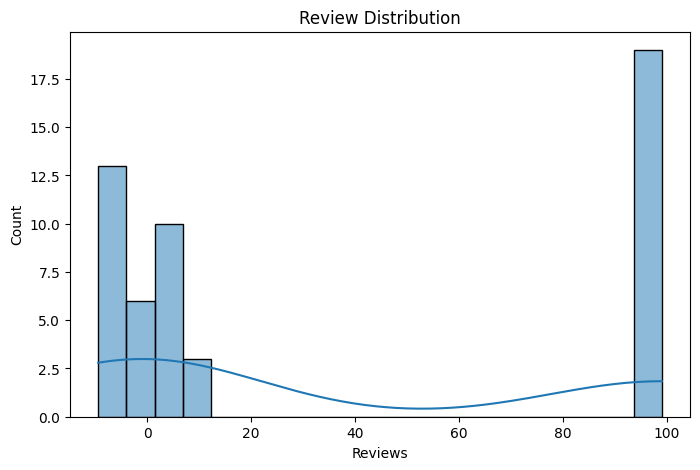

In [ ]:
#univariate analysis
#review distribution
plt.figure(figsize=(8,5))
sns.histplot(ent['Reviews'], bins=20, kde=True)
plt.title('Review Distribution')
plt.show()

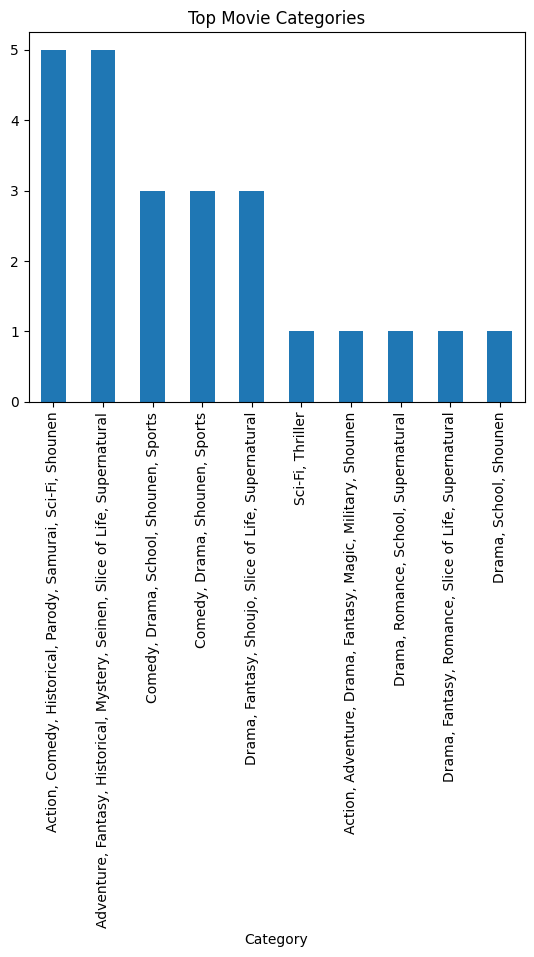

In [ ]:
#Top categoris
ent['Category'].value_counts().head(10).plot(kind='bar')
plt.title('Top Movie Categories')
plt.show()

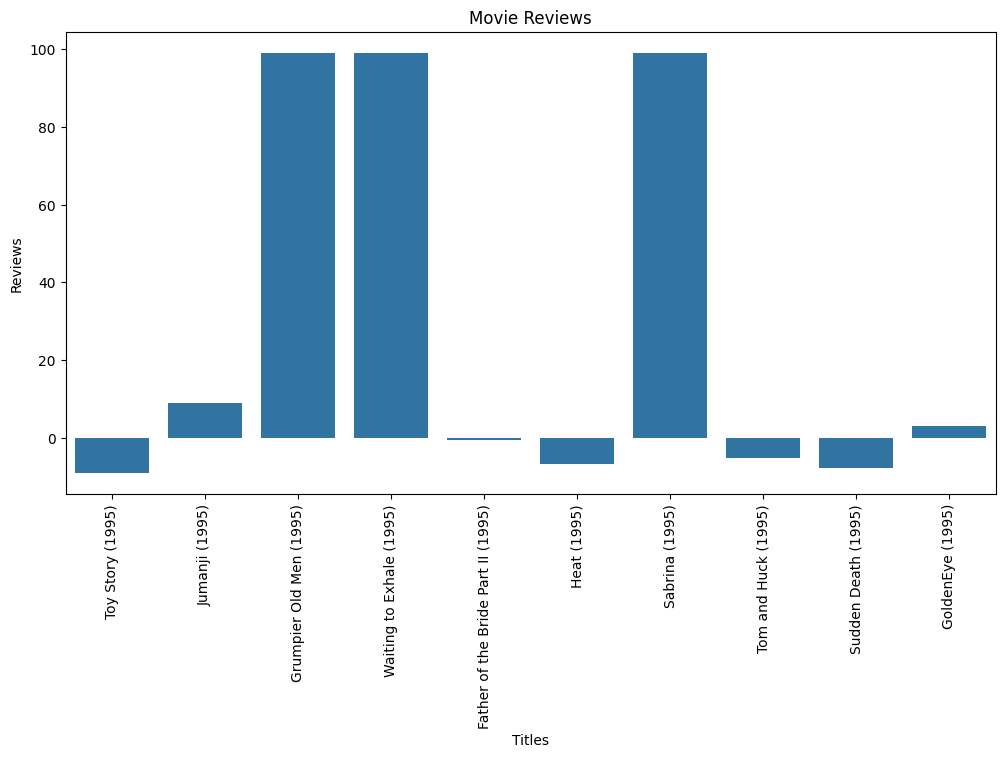

In [ ]:
#Bivariate analysis
plt.figure(figsize=(12,6))
sns.barplot(x='Titles', y='Reviews', data=ent.head(10))
plt.xticks(rotation=90)
plt.title('Movie Reviews')
plt.show()

In [ ]:
#content based recommendation sys
tfidf = TfidfVectorizer(stop_words='english')

ent['Category'] = ent['Category'].fillna('')

tfidf_matrix = tfidf.fit_transform(ent['Category'])

print(tfidf_matrix.shape)

(51, 34)


In [ ]:
#cosine similarity matrix
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

print(cosine_sim)

[[1.         0.09421367 0.         ... 0.12767481 0.16772551 0.31295101]
 [0.09421367 1.         0.16662513 ... 0.22332745 0.         0.        ]
 [0.         0.16662513 1.         ... 0.13383076 0.         0.        ]
 ...
 [0.12767481 0.22332745 0.13383076 ... 1.         0.47083158 0.17020003]
 [0.16772551 0.         0.         ... 0.47083158 1.         0.64107498]
 [0.31295101 0.         0.         ... 0.17020003 0.64107498 1.        ]]


In [ ]:
#Recommendation functions
# Create a Series that maps movie titles to their index
indices = pd.Series(ent.index, index=ent['Titles'])

def recommend_movies(title, cosine_sim=cosine_sim):

    idx = indices[title]

    sim_scores = list(enumerate(cosine_sim[idx]))

    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)

    sim_scores = sim_scores[1:6]

    movie_indices = [i[0] for i in sim_scores]

    return ent['Titles'].iloc[movie_indices]

In [ ]:
recommend_movies('Toy Story (1995)')

,Titles
25,Othello (1995)
16,Sense and Sensibility (1995)
11,Dracula: Dead and Loving It (1995)
10,"American President, The (1995)"
45,When Night Is Falling (1995)


In [ ]:
#model evaluation
print(cosine_sim[0])

[1.         0.09421367 0.         0.         0.         0.42359591
 0.         0.10686286 0.         0.         0.54177871 0.58035645
 0.         0.08421361 0.42359591 0.43279274 0.58230377 0.12767481
 0.         0.17811026 0.15484034 0.26510856 0.10403276 0.11097268
 0.         0.62594265 0.39703131 0.12767481 0.12767481 0.
 0.39430628 0.25267036 0.15484034 0.12767481 0.25267036 0.474735
 0.17942927 0.1620291  0.08147575 0.51531804 0.12938023 0.
 0.34279311 0.42359591 0.15484034 0.52359466 0.25267036 0.
 0.12767481 0.16772551 0.31295101]


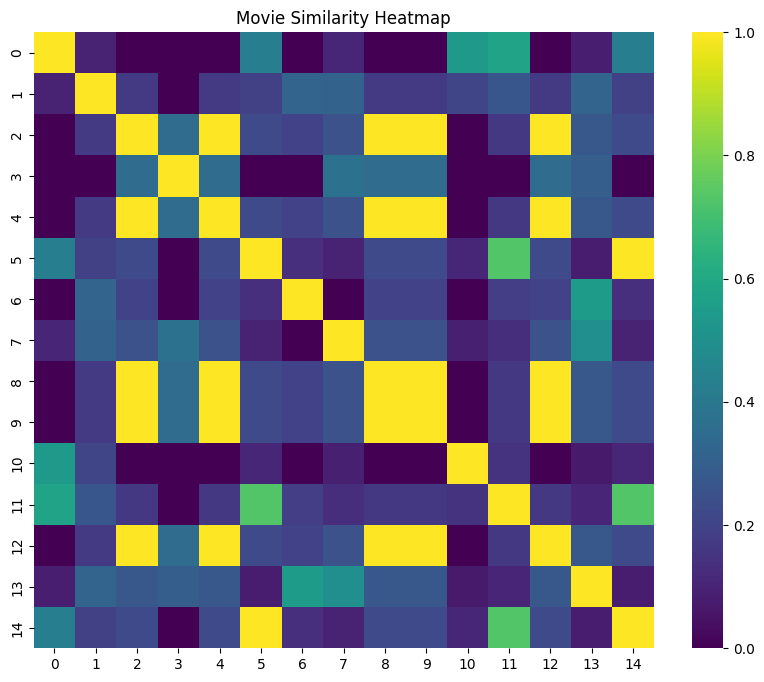

In [ ]:
#visualization
plt.figure(figsize=(10,8))
sns.heatmap(cosine_sim[:15,:15], cmap='viridis')
plt.title('Movie Similarity Heatmap')
plt.show()

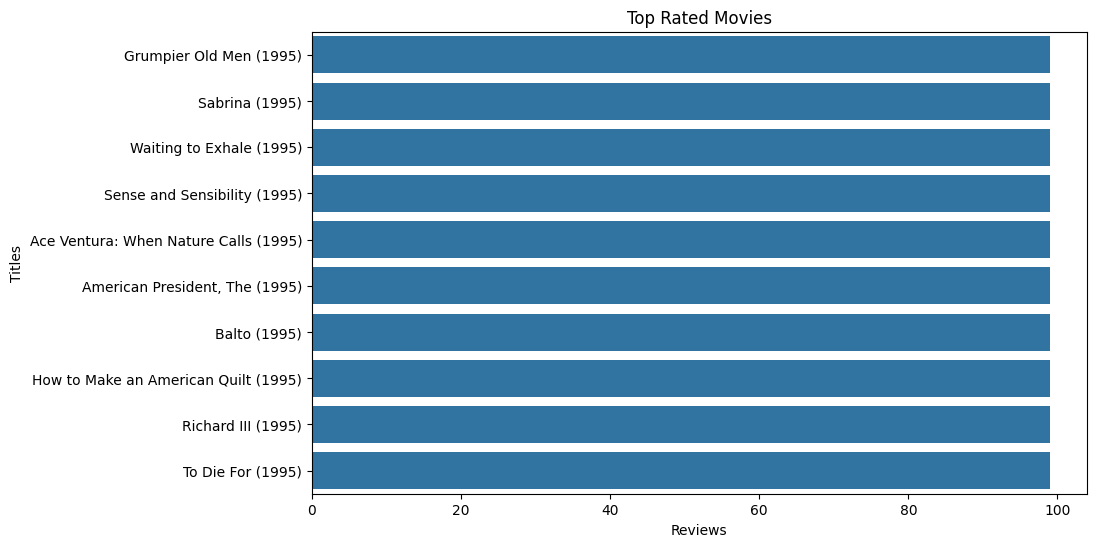

In [ ]:
#top rated movies
top_movies = ent.sort_values(by='Reviews', ascending=False).head(10)

plt.figure(figsize=(10,6))
sns.barplot(x='Reviews', y='Titles', data=top_movies)
plt.title('Top Rated Movies')
plt.show()

In [ ]:
#Model Interpretation
'''Movies with similar genres/categories are recommended.
TF-IDF converts textual category data into numerical vectors.
Cosine similarity identifies similar movies.
The model recommends movies with matching viewing patterns'''

In [ ]:
#Business Benefits
'''Better movie recommendations.
Increased customer watch time.
Higher customer engagement.
Better customer retention.
Improved platform revenue.
Automated recommendation process.'''

In [ ]:
#Final conclusion
'''The gaming recommendation engine recommends games based on similar users.

The entertainment recommendation engine recommends movies based on content similarity.

These recommendation systems help businesses improve:

Sales
Customer engagement
Retention
Customer satisfaction
Business growth'''